In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal

In [2]:
priors = [0.3, 0.3, 0.4]

m1  = np.array([ 1.0,  1.0,  1.0])          
m2  = np.array([ 1.0, -1.0, -1.0])        
m3a = np.array([-1.0,  1.0, -1.0])        
m3b = np.array([-1.0, -1.0,  1.0])          

C1  = np.array([[1.0,  0.3,  0.0],
                [0.3,  0.8,  0.2],
                [0.0,  0.2,  1.2]])
C2  = np.array([[0.9, -0.2,  0.1],
                [-0.2, 1.1,  0.0],
                [0.1,  0.0,  1.0]])
C3a = np.array([[1.2,  0.0,  0.3],
                [0.0,  0.9, -0.2],
                [0.3, -0.2,  0.8]])
C3b = np.array([[0.8,  0.2, -0.1],
                [0.2,  1.0,  0.3],
                [-0.1, 0.3,  1.1]])

means = [m1, m2, m3a, m3b]
covs  = [C1, C2, C3a, C3b]
names = ['m1', 'm2', 'm3a', 'm3b']
avg_std = np.mean([np.sqrt(np.trace(C) / 3) for C in covs])
print('Average standard deviation =', round(avg_std, 3))
for i in range(4):
    for j in range(i + 1, 4):
        d = np.linalg.norm(means[i] - means[j])
        print(names[i], '-', names[j], ': distance =', round(d, 3),
              '=', round(d / avg_std, 2), 'x average std')

Average standard deviation = 0.992
m1 - m2 : distance = 2.828 = 2.85 x average std
m1 - m3a : distance = 2.828 = 2.85 x average std
m1 - m3b : distance = 2.828 = 2.85 x average std
m2 - m3a : distance = 2.828 = 2.85 x average std
m2 - m3b : distance = 2.828 = 2.85 x average std
m3a - m3b : distance = 2.828 = 2.85 x average std


In [3]:
rng = np.random.default_rng(5644)       
N = 10000

u = rng.random(N)
L = np.zeros(N, dtype=int)
L[u < 0.3] = 1
L[(u >= 0.3) & (u < 0.6)] = 2
L[u >= 0.6] = 3
N1 = np.sum(L == 1)
N2 = np.sum(L == 2)
N3 = np.sum(L == 3)

X = np.zeros((N, 3))
X[L == 1] = rng.multivariate_normal(m1, C1, N1, method='cholesky')
X[L == 2] = rng.multivariate_normal(m2, C2, N2, method='cholesky')

idx3 = np.where(L == 3)[0]
from_a = rng.random(N3) < 0.5
X[idx3[from_a]]  = rng.multivariate_normal(m3a, C3a, np.sum(from_a), method='cholesky')
X[idx3[~from_a]] = rng.multivariate_normal(m3b, C3b, np.sum(~from_a), method='cholesky')

np.savetxt('Q2_data.csv', np.column_stack([X, L]), delimiter=',',
           header='x1,x2,x3,label', comments='')

print('Class 1 samples:', N1)
print('Class 2 samples:', N2)
print('Class 3 samples:', N3, '(component a:', np.sum(from_a), ', component b:', np.sum(~from_a), ')')

Class 1 samples: 2981
Class 2 samples: 2995
Class 3 samples: 4024 (component a: 1966 , component b: 2058 )


In [4]:
def confusion_matrix(D, L):
    CM = np.zeros((3, 3))
    for i in range(1, 4):
        for j in range(1, 4):
            CM[i-1, j-1] = np.sum((D == i) & (L == j)) / np.sum(L == j)
    return CM

def plot_decisions(ax, D, title):
    markers = {1: 'o', 2: '^', 3: 's'}
    for j in [1, 2, 3]:                   
        ok = (L == j) & (D == j)
        ax.scatter(X[ok, 0], X[ok, 1], X[ok, 2], marker=markers[j], s=6,
                   c='green', alpha=0.25, label='L=' + str(j) + ' correct')
    for j in [1, 2, 3]:                   
        bad = (L == j) & (D != j)
        ax.scatter(X[bad, 0], X[bad, 1], X[bad, 2], marker=markers[j], s=6,
                   c='red', alpha=0.6, label='L=' + str(j) + ' wrong')
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.set_zlabel('x3')
    ax.set_title(title)
    ax.view_init(elev=30, azim=45)

In [5]:
px1 = multivariate_normal.pdf(X, m1, C1)
px2 = multivariate_normal.pdf(X, m2, C2)
px3 = 0.5 * multivariate_normal.pdf(X, m3a, C3a) + 0.5 * multivariate_normal.pdf(X, m3b, C3b)

G = np.column_stack([px1 * priors[0], px2 * priors[1], px3 * priors[2]])

D_map = np.argmax(G, axis=1) + 1    
CM_map = confusion_matrix(D_map, L)
Pe_map = np.mean(D_map != L)

print('Confusion matrix P(D=i|L=j)  (rows = D, columns = L):')
print(np.round(CM_map, 4))
print('Estimated minimum P(error) =', round(Pe_map, 4))

Confusion matrix P(D=i|L=j)  (rows = D, columns = L):
[[0.8138 0.0621 0.0813]
 [0.0721 0.8471 0.0639]
 [0.1141 0.0908 0.8549]]
Estimated minimum P(error) = 0.1597


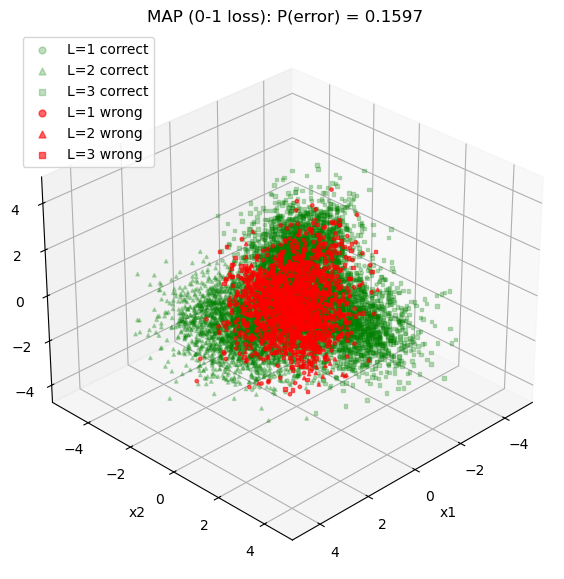

In [6]:
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(projection='3d', computed_zorder=False)
plot_decisions(ax, D_map, 'MAP (0-1 loss): P(error) = ' + str(round(Pe_map, 4)))
ax.legend(loc='upper left', markerscale=2)

plt.savefig('Q2_Fig1_MAP.png', dpi=300)
plt.show()

In [7]:
Lambda10  = np.array([[0, 1,  10],
                      [1, 0,  10],
                      [1, 1,   0]])
Lambda100 = np.array([[0, 1, 100],
                      [1, 0, 100],
                      [1, 1,   0]])

posterior = G / np.sum(G, axis=1, keepdims=True)

def erm_decide(Lambda):
    risk = posterior @ Lambda.T
    return np.argmin(risk, axis=1) + 1

def average_risk(D, L, Lambda):
    total = 0
    for n in range(len(L)):
        total += Lambda[D[n] - 1, L[n] - 1]
    return total / len(L)

D_10  = erm_decide(Lambda10)
D_100 = erm_decide(Lambda100)

for name, D, Lam in [('Lambda10', D_10, Lambda10), ('Lambda100', D_100, Lambda100)]:
    print('=====', name, '=====')
    print('Confusion matrix P(D=i|L=j)  (rows = D, columns = L):')
    print(np.round(confusion_matrix(D, L), 4))
    print('Minimum expected risk (ERM)     =', round(average_risk(D, L, Lam), 4))
    print('Risk if MAP decisions were used =', round(average_risk(D_map, L, Lam), 4))
    print('P(error)                        =', round(np.mean(D != L), 4))
    print('Fraction of samples decided 3   =', round(np.mean(D == 3), 4))
    print()

===== Lambda10 =====
Confusion matrix P(D=i|L=j)  (rows = D, columns = L):
[[0.529  0.0174 0.0097]
 [0.0305 0.6401 0.0084]
 [0.4405 0.3426 0.9819]]
Minimum expected risk (ERM)     = 0.3212
Risk if MAP decisions were used = 0.6853
P(error)                        = 0.2555
Fraction of samples decided 3   = 0.629

===== Lambda100 =====
Confusion matrix P(D=i|L=j)  (rows = D, columns = L):
[[2.097e-01 7.000e-04 5.000e-04]
 [4.000e-03 3.462e-01 1.200e-03]
 [7.863e-01 6.531e-01 9.983e-01]]
Minimum expected risk (ERM)     = 0.5014
Risk if MAP decisions were used = 5.9413
P(error)                        = 0.4321
Fraction of samples decided 3   = 0.8317



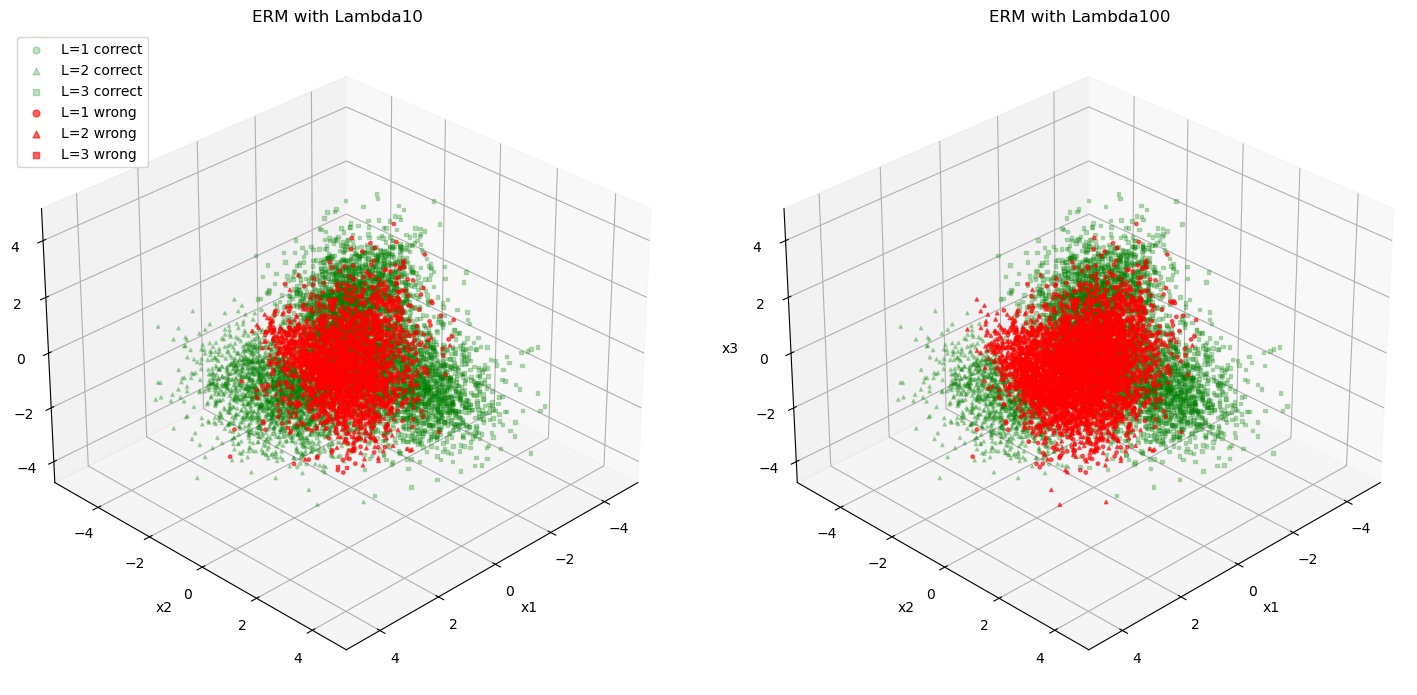

In [8]:
fig = plt.figure(figsize=(15, 7))

ax1 = fig.add_subplot(1, 2, 1, projection='3d', computed_zorder=False)
plot_decisions(ax1, D_10, 'ERM with Lambda10')
ax1.legend(loc='upper left', markerscale=2)

ax2 = fig.add_subplot(1, 2, 2, projection='3d', computed_zorder=False)
plot_decisions(ax2, D_100, 'ERM with Lambda100')

plt.tight_layout()
plt.savefig('Q2_Fig2_ERM.png', dpi=300)
plt.show()